# hiNiche: mouse midbrain Stereo-seq analysis

Multi-scale (spot / cell / niche) cell-type deconvolution and niche discovery on Stereo-seq mouse brain data (bin4).

> **Environment:** run this notebook in the main **`hiNiche`** environment (`environment.yml`). Input: `bin4_adult_brain.h5ad`, which already holds the spot -> cell assignment (`obsm["cell_assignment"]`), and the reference profiles `lambda_matrix.csv`.

## 1. Setup and imports

In [30]:
import os
import sys
# cupy (used by rapids_singlecell) compiles GPU kernels at runtime and needs the CUDA headers shipped inside the conda environment
os.environ.setdefault("CUDA_PATH", os.path.join(sys.prefix, "targets", "x86_64-linux"))

# --- Project modules ---
import config
import utils
from train import run_train_seq

# --- Standard library ---
import json
import warnings
from collections import Counter

# --- Data handling ---
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import scipy.sparse as sp

# --- Deep learning ---
import torch
import torch.nn.functional as F

# --- Clustering ---
import rapids_singlecell as rsc     # GPU-accelerated neighbors / Leiden / UMAP
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

# --- Plotting ---
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Parameter configuration

In [31]:
SAMPLE = "Mouse_midbrain_Stereo_single_slice"

# Data paths
h5_path     = f"DATA/{SAMPLE}/bin4_adult_brain.h5ad"
refile_path = f"DATA/{SAMPLE}/lambda_matrix.csv"

#Patch save path
PATCH_LOC = f"DATA/{SAMPLE}/mini_batch_cache"

#Model save path
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Cell-type color map defined in config.py
celltype_color = getattr(config, "colormap_mouse_brain_41")
umap_color = getattr(config, "umap_40")

# Model / training hyperparameters
Patch_size  = 512
graph_knn   = 12
niche_knn   = 15
lr          = 0.005
num_epochs  = 30
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
alpha       = 1
beta        = 1
seed        = 42
device      = "cuda:0"

## 3. Data loading and preprocessing

### 3.1 Load counts and spot positions

In [32]:
# Reference expression profiles (genes x cell types)
ref_df = pd.read_csv(refile_path, index_col = 0)

# Load bin4 counts; obsm["cell_assignment"] is the precomputed spot -> cell matrix
adata = sc.read_h5ad(h5_path)

# Grid (bin index) and pixel coordinates
adata.obsm["spatial_grid"]  = adata.obs[["bin_x_count", "bin_y_count"]].to_numpy()
adata.obsm["spatial_pixel"] = np.asarray(adata.obsm["spatial_pixel"])
adata

AnnData object with n_obs × n_vars = 5893711 × 26177
    obs: 'bin_x_px', 'bin_y_px', 'bin_x_um', 'bin_y_um', 'bin_x_count', 'bin_y_count', 'in_cell', 'cell_id'
    uns: 'cell_ids', 'coordinate_info'
    obsm: 'cell_assignment', 'incell_mask', 'spatial_bin4count', 'spatial_pixel', 'spatial_um', 'spatial_grid'

### 3.2 Quality control, background filtering, and normalization

In [33]:
# Keep raw counts before normalization
adata.layers["counts"] = adata.X.copy()

adata.var_names_make_unique()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

# Flag low-count background regions and drop them
adata = utils.background_detector(adata, threshold = 50, n_neighs =4, n_rings = 4)
print(f"[Log] original adata size is {adata.shape}")

before = adata.shape[0]
adata = adata[adata.obs["low_count_region"] < 1]
after = adata.shape[0]
print(f"[Log] filtering background: {before} spots to {after} spots")

# Library-size normalization + log transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

[Log] original adata size is (5893711, 26177)
[Log] filtering background: 5893711 spots to 5549415 spots


### 3.3 Align genes with the reference

In [34]:
# Restrict to genes shared between the data and the reference
overlap_gs = adata.var.index.intersection(ref_df.index)
print(f"[Log] num of gene overlap {len( overlap_gs )}")

adata.obsm["X_mle"] = adata.layers["counts"][:, adata.var_names.isin(overlap_gs)]   # raw counts
adata.obsm["X_input"] = adata[:, adata.var_names.isin(overlap_gs)].X                # normalized model input

print(f"[Log] input gene number is {len(overlap_gs)}")
ref_matrix = ref_df.loc[overlap_gs].values
ref_matrix = np.array(ref_matrix)

celltypes = list(ref_df.columns)
print(f"[Log] rna ref size is {ref_matrix.shape}")

[Log] num of gene overlap 5166
[Log] input gene number is 5166
[Log] rna ref size is (5166, 41)


## 4. Build the spot / cell / niche hierarchy

### 4.1 Spot-to-cell and spot-to-niche assignment

In [35]:
# Spot -> cell assignment from the precomputed cell segmentation in the h5ad
S_s2c_all, cell_background_mask = utils.spot2cell_from_assignment(adata.obsm["cell_assignment"], max_spots_per_cell=100, min_spots_per_cell=3)
print(f"[Log] {S_s2c_all.shape[1]} cells are detected")

# Spot -> niche assignment: each niche is a cell plus its nearest neighbors
S_s2n_all, niche_background_mask, active_niche_indices, S_c2n_all = utils.spot2niche_by_cell_knn(adata.obsm["spatial_grid"], S_s2c_all, k_niche=niche_knn)
background_mask = {"cell": cell_background_mask, "niche":niche_background_mask}

[Log] Active Cells (before filtering): 54838
[Log] Valid Cells (3 <= spots <= 100): 47042
[Log] Filtered Cells (< 3 spots): 549
[Log] Filtered Cells (> 100 spots): 7247
[Log] 47042 cells are detected
[Log] Active Niches: 47042, Cells per Niche (k): 15


### 4.2 Spatial KNN graphs

In [36]:
# Spatial KNN graphs at spot and cell level
spot_edges = utils.build_spot_knn_graph(adata.obsm["spatial_grid"], graph_knn)
cell_edges = utils.build_cell_knn_graph(adata.obsm["spatial_grid"], S_s2c_all, graph_knn)
# Niche graph: reuses the cell KNN graph (one niche per cell), same k as spot/cell graphs
niche_edges = cell_edges

[Log] 67171214 edges generated from 5549415 nodes (k=12)
[Log] 634832 edges generated from 47042 nodes (k=12)


### 4.3 Spatial blocking and subgraph caching

In [37]:
# Split the slide into overlapping spatial blocks (core + halo) for mini-batch training
batch_mask, block_ids = utils.make_block_masks(adata.obsm["spatial_grid"], Patch_size=Patch_size, halo=32, S_s2c=S_s2c_all, S_s2n=S_s2n_all)

# Build and cache per-block subgraph data to disk
utils.build_subgraph_data(adata, ref_matrix, spot_edges, cell_edges, niche_edges,
                          S_s2c_all, S_s2n_all, S_c2n_all, background_mask, batch_mask, block_ids, PATCH_LOC)
print(f"[Log] Original ST is patchfied to {len(block_ids)} blocks with avg {batch_mask['spot_level_core'].sum(dim=1).float().mean().item():.0f} spots, {batch_mask['cell_level_core'].sum(dim=1).float().mean().item():.0f} cells and {batch_mask['niche_level_core'].sum(dim=1).float().mean().item():.0f} niches per block")

[Log] Generating spot masks for 42 blocks...


[Log] Building & saving mini-batches: 100%|██████████| 42/42 [03:02<00:00,  4.34s/it]


[Log] Saved 29 blocks → DATA/Mouse_midbrain_Stereo_single_slice/mini_batch_cache
[Log] Original ST is patchfied to 42 blocks with avg 132129 spots, 1153 cells and 1315 niches per block


## 5. Model training

In [38]:
emb_all, slice_id = run_train_seq(total_unit_number_per_level = {"spot": S_s2c_all.shape[0], "cell": S_s2c_all.shape[1], "niche": S_s2n_all.shape[1]},
                                  PATCH_LOC = PATCH_LOC,
                                  MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                  ref_matrix = ref_matrix,
                                  lr = lr,
                                  in_dim = len(overlap_gs),
                                  hidden_dim = len(celltypes),
                                  num_epochs = num_epochs,
                                  edge_drop = edge_drop, 
                                  member_drop = member_drop,
                                  neg_samples = neg_samples,
                                  tau = tau,
                                  alpha = alpha,
                                  beta = beta,
                                  seed = seed,
                                  device = device)

Epoch 30: 100%|██████████| 29/29 [00:05<00:00,  5.39it/s, cl=5.0759, nll=337.1638, entp=-6.4103]


Training finished!
Model saved to DATA/Mouse_midbrain_Stereo_single_slice/checkpoint.pt


generating embeddings (slice 0)...: 100%|██████████| 29/29 [00:06<00:00,  4.40it/s]


## 6. Visualization

### 6.1 Spot- and cell-level cell-type maps

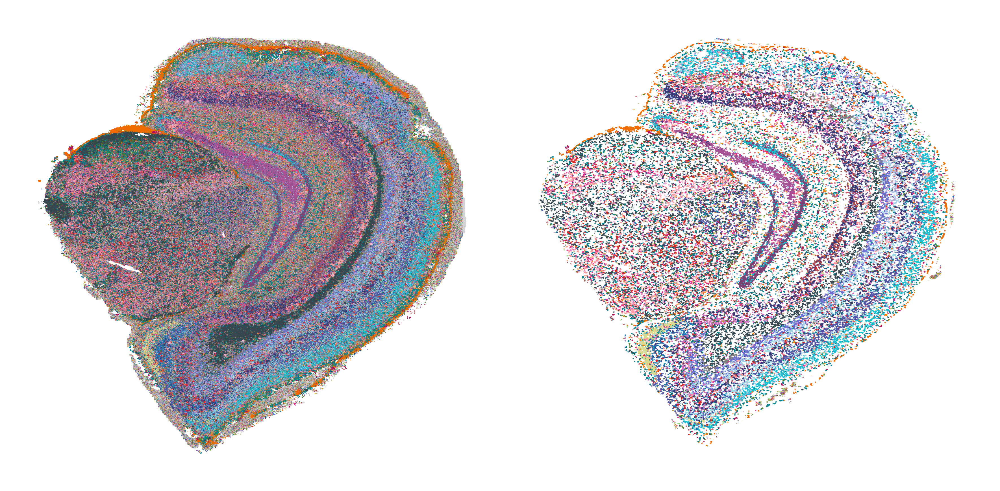

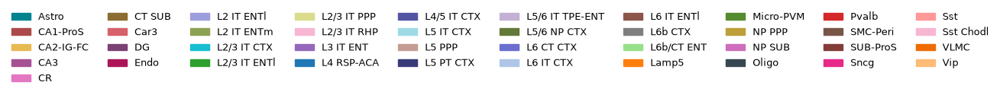

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3), dpi=600)   # left: spot level, right: cell level

keys = ["spot", "cell"]
labels_all = {}
for i, ax in enumerate(axes):
    check = keys[i]
    x_raw, y_raw = adata.obsm["spatial_pixel"][:, 0], adata.obsm["spatial_pixel"][:, 1]

    # Cell-type probabilities
    prob = F.softmax(emb_all[check], dim=1)
    max_prob_raw, max_idx_raw = torch.max(prob, dim=1)

    if check == "cell":
        # Broadcast each cell's prediction to its spots (spot -> cell mapping)
        S = S_s2c_all.coalesce()
        rows, cols = S.indices()[0], S.indices()[1]
        spot2target = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
        spot2target[rows] = cols
        max_idx = torch.where(spot2target >= 0, max_idx_raw[spot2target], torch.tensor(-1, device=S.device))
        max_prob = torch.where(spot2target >= 0, max_prob_raw[spot2target], torch.tensor(0.0, device=S.device))
    else:
        max_prob, max_idx = max_prob_raw, max_idx_raw

    # --- Label assignment ---
    cell_labels = []
    for j in range(len(max_prob)):
        # max_idx == -1: the spot does not belong to any valid cell
        if max_idx[j] == -1:
            cell_labels.append("filtered")
        elif max_prob[j] < 0.1:
            cell_labels.append("ambiguous")
        else:
            cell_labels.append(celltypes[max_idx[j]])
    labels_all[check] = cell_labels

    colors = [celltype_color[name] for name in cell_labels]
    ax.scatter(x_raw, y_raw, c=colors, s=0.5, marker='.', linewidths=0)
    ax.invert_yaxis()
    ax.axis("off")

plt.tight_layout()
plt.show()

# --- Legend ---
cell_type = np.asarray(celltypes)[F.softmax(emb_all["spot"], dim=1).argmax(1).cpu().numpy()]
handles = [mpatches.Patch(color=celltype_color.get(c, "#cccccc"), label=c) for c in np.unique(cell_type)]
figL, axL = plt.subplots(figsize=(11, 0.6)); axL.axis("off")
axL.legend(handles=handles, ncol=10, frameon=False, loc="center", fontsize=9)
plt.show()

### 6.2 Niche clustering (UMAP + spatial map)

niche: 21 clusters


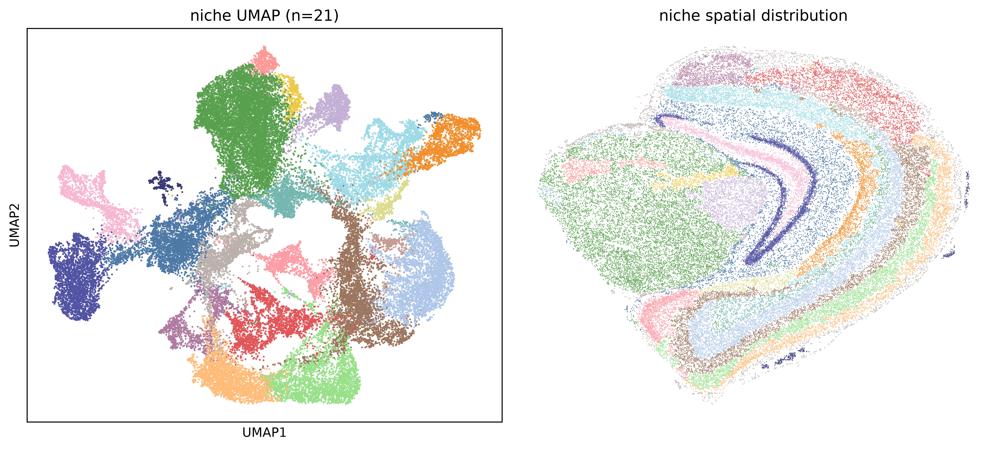

In [40]:
import torch
torch.cuda.empty_cache()

resolution = 0.5   # Leiden resolution; higher -> more clusters
emb_k = 50

# --- 1. Cluster niche embeddings (Leiden) + UMAP, sharing one neighbor graph ---
adata_tmp = ad.AnnData(emb_all["niche"].numpy())
rsc.pp.neighbors(adata_tmp, use_rep='X', n_neighbors=emb_k)
rsc.tl.leiden(adata_tmp, resolution=resolution, random_state=seed)
rsc.tl.umap(adata_tmp, random_state=seed)
niche_label = adata_tmp.obs['leiden'].astype(int).values
niche_umap = adata_tmp.obsm["X_umap"]
clusters_id = {"niche": niche_label}
n_clusters = len(np.unique(niche_label))
print(f"niche: {n_clusters} clusters")

# --- 2. Estimate each cell's position from S_s2c_all (mean of its spots' coordinates) ---
S = S_s2c_all.coalesce()
s_rows, c_cols = S.indices()
n_cell = S.size(1)
spatial = torch.as_tensor(adata.obsm["spatial_pixel"], dtype=torch.float32, device=S.device)

cell_pos = torch.zeros((n_cell, 2), device=S.device).index_add_(0, c_cols, spatial[s_rows])
cell_cnt = torch.zeros(n_cell, device=S.device).index_add_(0, c_cols, torch.ones_like(c_cols, dtype=torch.float32))
cell_pos /= cell_cnt.clamp(min=1).unsqueeze(1)

# --- 3. Map niche clusters back to cells ---
cell_niche = torch.full((n_cell,), -1, dtype=torch.long, device=S.device)
active = torch.as_tensor(active_niche_indices, device=S.device).long()
cell_niche[active] = torch.as_tensor(niche_label, device=S.device).long()

keep = (cell_niche >= 0) & (cell_cnt > 0)
pos = cell_pos[keep].cpu().numpy()
ids = cell_niche[keep].cpu().numpy()

# --- 4. Left: niche UMAP; right: niche spatial distribution at cell level (umap_40 colors) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=600)

axes[0].scatter(niche_umap[:, 0], niche_umap[:, 1],
                c=[umap_color[f"Cluster_{v}"] for v in niche_label], s=2, linewidths=0)
axes[0].set_title(f"niche UMAP (n={n_clusters})")
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_xlabel("UMAP1"); axes[0].set_ylabel("UMAP2")

axes[1].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v}"] for v in ids], s=2, marker='.', linewidths=0)
axes[1].set_title("niche spatial distribution")
axes[1].invert_yaxis(); axes[1].axis("off")

plt.tight_layout()
plt.show()

### 6.3 Merge niches by cell-type composition

21 niche clusters -> 20 merged
  [3, 17] -> 3


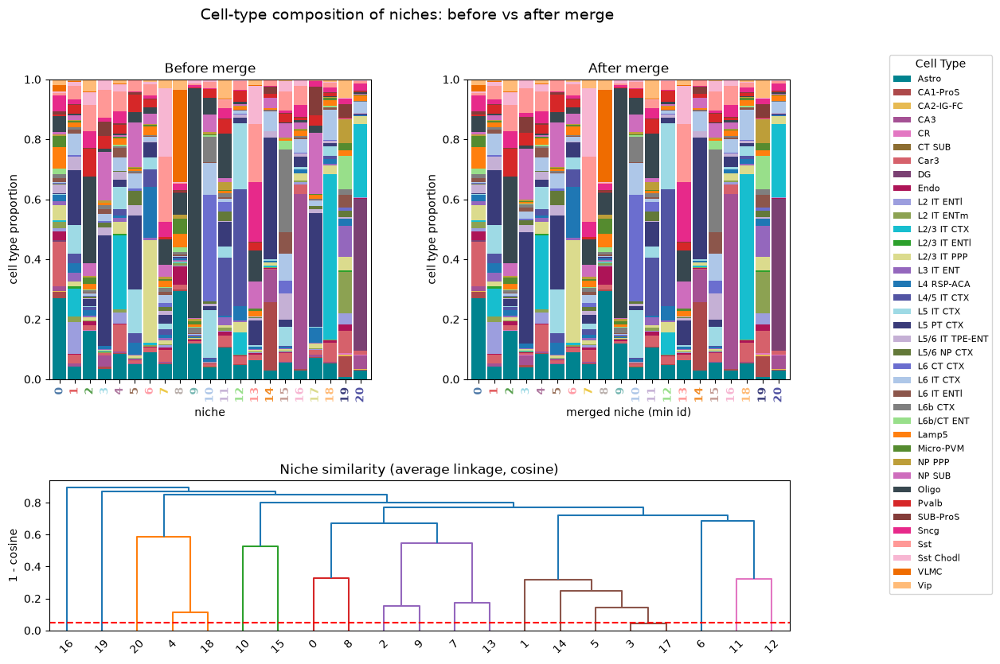

In [ ]:
# ---- Cell-type prediction (softmax temperature does not affect argmax, so it is comparable before/after) ----
cell_type = np.asarray(celltypes)[F.softmax(emb_all["cell"], dim=1).argmax(1).cpu().numpy()]

# ---- Composition table (before merge) ----
df_counts = pd.crosstab(np.asarray(clusters_id["niche"]), cell_type)

# ---- Hierarchical clustering + merge ----
comp = df_counts.div(df_counts.sum(1), axis=0)              # row-normalized composition
Z = linkage(comp.values, method="average", metric="cosine")
#Z = linkage(comp.values, method="ward", metric="euclidean")

merge_thresh = 0.05
merged = fcluster(Z, t=merge_thresh, criterion="distance")
group_members = {}
for old, g in zip(comp.index, merged):
    group_members.setdefault(g, []).append(int(old))
old2new = {o: min(members) for members in group_members.values() for o in members}   # smallest id in each group becomes the new label

print(f"{len(comp)} niche clusters -> {len(set(old2new.values()))} merged")
for rep in sorted(set(old2new.values())):
    members = sorted(o for o, r in old2new.items() if r == rep)
    if len(members) > 1:
        print(f"  {members} -> {rep}")

niche_merged = np.array([old2new[l] for l in clusters_id["niche"]])
clusters_id["niche_merged"] = niche_merged

# ---- Composition table (after merge) ----
dfm = pd.crosstab(niche_merged, cell_type)

# ---- Convert to proportions (row-normalized, each bar stacks to 1) ----
comp_before = df_counts.div(df_counts.sum(1), axis=0)      # same as comp
comp_after  = dfm.div(dfm.sum(1), axis=0)

# ================= Layout: top row before/after merge, bottom row full-width dendrogram =================
fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], hspace=0.45, wspace=0.3)
ax_before = fig.add_subplot(gs[0, 0])
ax_after  = fig.add_subplot(gs[0, 1])
ax_dendro = fig.add_subplot(gs[1, :])

def stacked(ax, df, title, xlabel):
    """Stacked bar chart of cell-type proportions per niche; x tick labels colored by niche."""
    df.plot(kind="bar", stacked=True, ax=ax,
            color=[celltype_color[c] for c in df.columns], width=0.9, legend=False)
    for tick, nid in zip(ax.get_xticklabels(), df.index):
        tick.set_color(umap_color[f"Cluster_{nid % 40}"]); tick.set_fontweight("bold")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("cell type proportion")
    ax.set_ylim(0, 1)

stacked(ax_before, comp_before, "Before merge", "niche")
stacked(ax_after,  comp_after,  "After merge",  "merged niche (min id)")

# Single legend on the right (the before-merge panel has the most complete set of types)
handles, labels = ax_before.get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.0, 0.92), loc="upper left",
           title="Cell Type", prop={"size": 8})

# Bottom row: dendrogram + merge threshold line
dendrogram(Z, labels=comp.index.tolist(), ax=ax_dendro)
ax_dendro.axhline(merge_thresh, ls="--", c="r")
ax_dendro.set_ylabel("1 - cosine")
ax_dendro.set_title("Niche similarity (average linkage, cosine)")

fig.suptitle("Cell-type composition of niches: before vs after merge", fontsize=14)
plt.show()

### 6.4 Niche spatial map before vs. after merge

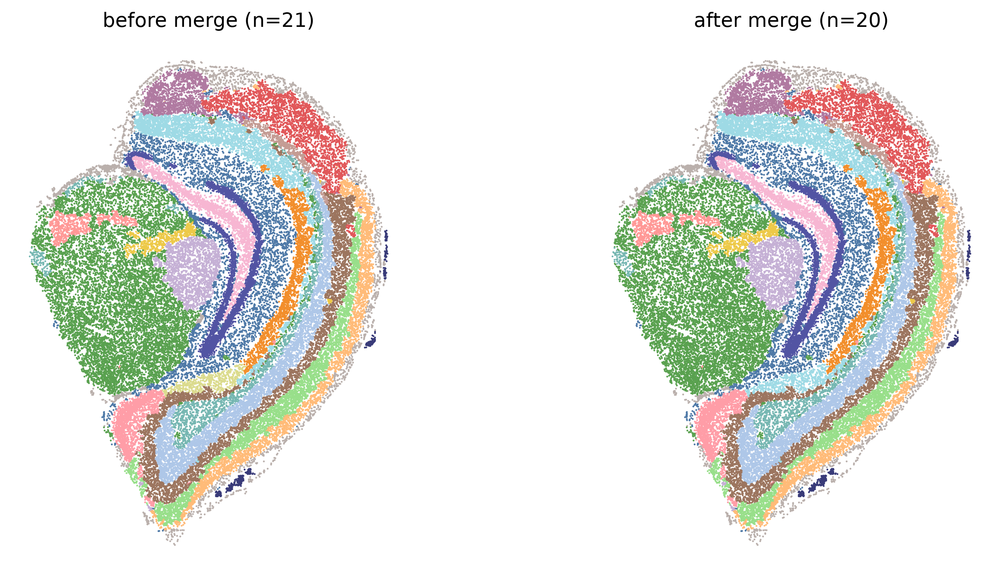

In [ ]:
# Merged niche label for each cell (remapped with old2new from the merge step)
ids_merged = np.array([old2new[i] for i in ids])

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=300)

# Left: before merge
axes[0].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in ids], s=5, marker='.', linewidths=0)
axes[0].set_title(f"before merge (n={len(np.unique(ids))})")

# Right: after merge
axes[1].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in ids_merged], s=5, marker='.', linewidths=0)
axes[1].set_title(f"after merge (n={len(np.unique(ids_merged))})")

for a in axes:
    a.invert_yaxis(); a.set_aspect("equal"); a.axis("off")
plt.tight_layout()
plt.show()

In [43]:
# --- Save niche cluster ids (before / after merge) and niche UMAP coordinates ---
# One row per niche (row order = rows of emb_all["niche"])
niche_out = pd.DataFrame({
    "center_cell":        torch.as_tensor(active_niche_indices).cpu().numpy(),   # cell index of the niche center
    "niche_before_merge": np.asarray(clusters_id["niche"]),
    "niche_after_merge":  np.asarray(clusters_id["niche_merged"]),
    "UMAP1":              niche_umap[:, 0],
    "UMAP2":              niche_umap[:, 1],
})
niche_out.index.name = "niche"
niche_out_path = f"DATA/{SAMPLE}/niche_clusters.csv"
niche_out.to_csv(niche_out_path)
print(f"[Log] saved {len(niche_out)} niches -> {niche_out_path}")
niche_out.head()

[Log] saved 47042 niches -> DATA/Mouse_midbrain_Stereo_single_slice/niche_clusters.csv


,center_cell,niche_before_merge,niche_after_merge,UMAP1,UMAP2
niche,,,,,
0,0,8,8,-2.972198,-1.024055
1,1,8,8,-3.395832,-0.879634
2,2,8,8,-3.034191,-1.051774
3,3,8,8,-3.099077,-0.954741
4,4,8,8,-3.368946,-0.896823


### 6.5 Cell embedding UMAP and spatial cell-type map

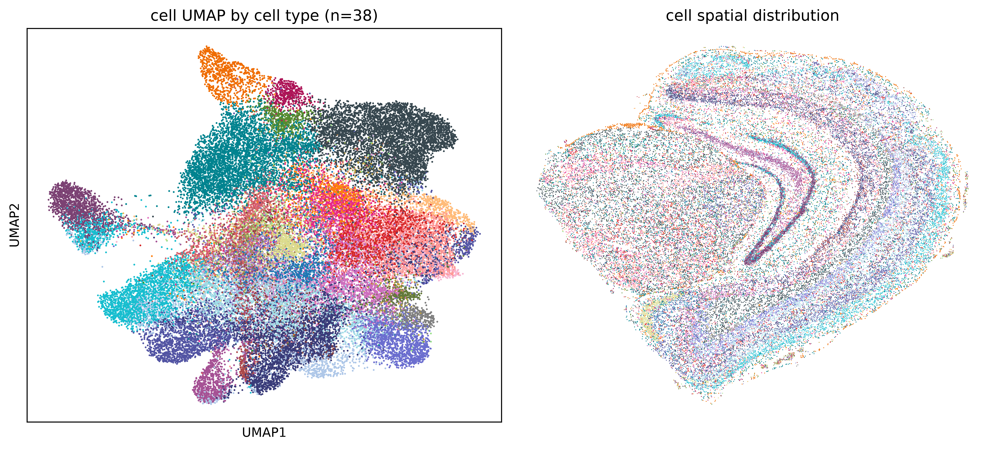

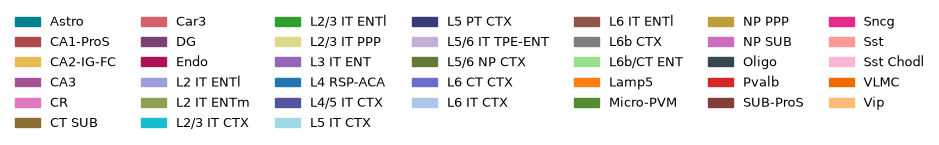

In [44]:
# --- 1. Cell embedding -> UMAP ---
adata_cell = ad.AnnData(emb_all["cell"].numpy())
sc.pp.neighbors(adata_cell, use_rep='X', n_neighbors=emb_k)
sc.tl.umap(adata_cell, random_state=seed)
cell_umap = adata_cell.obsm["X_umap"]

# --- 2. Cell type per cell (argmax) ---
cell_type = np.asarray(celltypes)[F.softmax(emb_all["cell"], dim=1).argmax(1).cpu().numpy()]
col = lambda arr: [celltype_color.get(c, "#cccccc") for c in arr]

# --- 3. Cell coordinates (mean of its spots) ---
S = S_s2c_all.coalesce()
s_rows, c_cols = S.indices()
n_cell = S.size(1)
spatial = torch.as_tensor(adata.obsm["spatial_pixel"], dtype=torch.float32, device=S.device)
cell_pos = torch.zeros((n_cell, 2), device=S.device).index_add_(0, c_cols, spatial[s_rows])
cell_cnt = torch.zeros(n_cell, device=S.device).index_add_(0, c_cols, torch.ones_like(c_cols, dtype=torch.float32))
cell_pos = (cell_pos / cell_cnt.clamp(min=1).unsqueeze(1)).cpu().numpy()
keep = cell_cnt.cpu().numpy() > 0

# --- 4. Left: cell UMAP colored by type; right: spatial map colored by type ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=600)
axes[0].scatter(cell_umap[:, 0], cell_umap[:, 1], c=col(cell_type), s=2, linewidths=0)
axes[0].set_title(f"cell UMAP by cell type (n={len(np.unique(cell_type))})")
axes[0].set_xticks([]); axes[0].set_yticks([]); axes[0].set_xlabel("UMAP1"); axes[0].set_ylabel("UMAP2")

axes[1].scatter(cell_pos[keep, 0], cell_pos[keep, 1], c=col(cell_type[keep]), s=2, marker='.', linewidths=0)
axes[1].set_title("cell spatial distribution")
axes[1].invert_yaxis(); axes[1].axis("off")
plt.tight_layout(); plt.show()
#plt.savefig("cell_type.png")

# --- Legend ---
handles = [mpatches.Patch(color=celltype_color.get(c, "#cccccc"), label=c) for c in np.unique(cell_type)]
figL, axL = plt.subplots(figsize=(11, 0.6)); axL.axis("off")
axL.legend(handles=handles, ncol=7, frameon=False, loc="center", fontsize=9)
plt.show()

## 7. Layer marker density with niche overlay

Expression density (weighted KDE) of cortical layer markers, drawn over the niche clusters.

[Log] saved -> DATA/Mouse_midbrain_Stereo_single_slice/layer_markers_density_niche_overlay.png


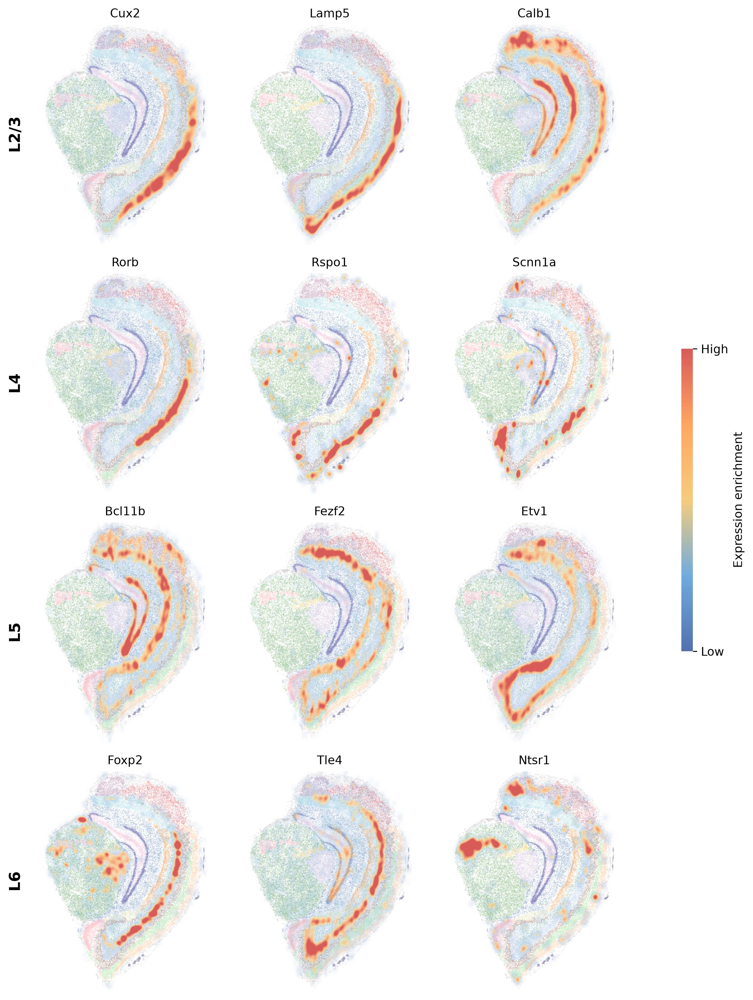

In [48]:
import matplotlib as mpl
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap

# Colormap of the gene density (enrichment) heat map, shared by all panels and the color bar
DENSITY_CMAP = LinearSegmentedColormap.from_list(
    "custom_gene_density_cmap",
    ["#5271ae", "#70acde", "#F5cc7d", "#ffa660", "#d85b59"])


def plot_gene_spatial_kde_roi(
    ax, adata, gene,
    x_min, x_max, y_min, y_max,
    spatial_key="spatial_grid", gridsize=300, cmap=None,
    invert_y=True, add_colorbar=False, bw_method=0.05,
    vmin=None, vmax=None, density_alpha=True, zorder=5,
):
    """Expression-weighted KDE of one gene inside an ROI."""
    x = adata.obsm[spatial_key][:, 0]
    y = adata.obsm[spatial_key][:, 1]
    mask = (x >= x_min) & (x <= x_max) & (y >= y_min) & (y <= y_max)
    x_roi, y_roi = x[mask], y[mask]

    expr = adata[:, gene].layers["counts"]
    expr = expr.toarray().reshape(-1) if hasattr(expr, "toarray") else np.asarray(expr).reshape(-1)
    expr_roi = expr[mask]

    valid = np.isfinite(expr_roi) & (expr_roi > 0)
    x_roi, y_roi, expr_roi = x_roi[valid], y_roi[valid], expr_roi[valid]
    if len(x_roi) < 2:
        raise ValueError("too few expressing spots in the ROI for a KDE")

    if cmap is None:
        cmap = DENSITY_CMAP

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, gridsize),
                         np.linspace(y_min, y_max, gridsize))
    kde = gaussian_kde(np.vstack([x_roi, y_roi]), weights=expr_roi, bw_method=bw_method)
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)

    if vmin is None: vmin = np.nanmin(zz)
    if vmax is None: vmax = np.nanpercentile(zz, 99)

    # Density as transparency: low density is transparent (niches show through), high density is opaque
    alpha = np.clip((zz - vmin) / (vmax - vmin + 1e-12), 0, 1) if density_alpha else None

    im = ax.imshow(zz, origin="lower", extent=[x_min, x_max, y_min, y_max],
                   cmap=cmap, aspect="equal", vmin=vmin, vmax=vmax,
                   alpha=alpha, zorder=zorder)                       # heat map on top
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    if invert_y: ax.invert_yaxis()
    ax.axis("off")
    if add_colorbar: plt.colorbar(im, ax=ax, fraction=0.046, pad=0.5)
    return im


# ================== Whole-slide extent + per-gene wrapper ==================
xy = adata.obsm["spatial_grid"]
FULL = dict(x_min=xy[:, 0].min(), x_max=xy[:, 0].max(),
            y_min=xy[:, 1].min(), y_max=xy[:, 1].max())

def plot_gene(ax, gene):
    plot_gene_spatial_kde_roi(ax=ax, adata=adata, gene=gene,
                              gridsize=300, add_colorbar=False, **FULL)

# ================== Niche clusters at cell level (bottom layer, grid coordinates) ==================
S = S_s2c_all.coalesce()
s_rows, c_cols = S.indices()[0], S.indices()[1]
n_cell = S.size(1)
grid = torch.as_tensor(adata.obsm["spatial_grid"], dtype=torch.float32, device=S.device)
cell_pos_grid = torch.zeros((n_cell, 2), device=S.device).index_add_(0, c_cols, grid[s_rows])
cell_cnt = torch.zeros(n_cell, device=S.device).index_add_(0, c_cols, torch.ones_like(c_cols, dtype=torch.float32))
cell_pos_grid = (cell_pos_grid / cell_cnt.clamp(min=1).unsqueeze(1)).cpu().numpy()

cn = cell_niche.cpu().numpy()     # niche cluster of each center cell (section 6.2)
keep_n = (cn >= 0) & (cell_cnt.cpu().numpy() > 0)
niche_coords = cell_pos_grid[keep_n]
niche_labels = cn[keep_n]

def overlay_niche(ax, alpha=0.2, s=2):
    ax.scatter(niche_coords[:, 0], niche_coords[:, 1],
               c=[umap_color[f"Cluster_{v % 40}"] for v in niche_labels],
               s=s, marker='.', linewidths=0, alpha=alpha, zorder=1)   # bottom layer

# ================== Marker genes ==================
genes_by_layer = {
    "L2/3": ["Cux2", "Lamp5", "Calb1"],
    "L4":   ["Rorb", "Rspo1", "Scnn1a"],
    "L5":   ["Bcl11b", "Fezf2", "Etv1"],
    "L6":   ["Foxp2", "Tle4", "Ntsr1"],
}
lower2name = {g.lower(): g for g in adata.var_names}
resolved = {}
for layer, gs in genes_by_layer.items():
    keep_g = []
    for g in gs:
        hit = lower2name.get(g.lower())
        (keep_g.append(hit) if hit else print(f"[skip] {layer}: {g} not in var_names"))
    resolved[layer] = keep_g

layers = [l for l in resolved if resolved[l]]
ncols  = max(len(resolved[l]) for l in layers)
nrows  = len(layers)

# ================== Grid: niches first, then the density heat map on top ==================
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows), dpi=300, squeeze=False)
for r, layer in enumerate(layers):
    gs = resolved[layer]
    for c in range(ncols):
        ax = axes[r][c]
        if c < len(gs):
            try:
                overlay_niche(ax)             # 1) bottom: niche clusters
                plot_gene(ax, gs[c])          # 2) top: gene density
                ax.set_title(gs[c], fontsize=10)
            except Exception as e:
                ax.axis("off"); print(f"[fail] {gs[c]}: {e}")
        else:
            ax.axis("off")
    axes[r][0].text(-0.12, 0.5, layer, transform=axes[r][0].transAxes,
                    ha="right", va="center", fontsize=13, fontweight="bold", rotation=90)

# ================== Enrichment legend: one shared color bar ==================
# Each panel is scaled to its own [min, 99th percentile], so the bar shows relative enrichment (low -> high)
fig.tight_layout(rect=[0, 0, 0.9, 1])
cax = fig.add_axes([0.92, 0.35, 0.015, 0.3])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 1), cmap=DENSITY_CMAP), cax=cax)
cb.set_ticks([0, 1]); cb.set_ticklabels(["Low", "High"])
cb.set_label("Expression enrichment", fontsize=10)
cb.outline.set_visible(False)

# ================== Save at high resolution ==================
fig_path = f"DATA/{SAMPLE}/layer_markers_density_niche_overlay.png"
fig.savefig(fig_path, dpi=600, bbox_inches="tight", facecolor="white")
print(f"[Log] saved -> {fig_path}")
plt.show()